[Data in Kaggle](https://www.kaggle.com/heesoo37/120-years-of-olympic-history-athletes-and-results?select=athlete_events.csv)

# Import the libraries

In [120]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the data

In [121]:
athlete = pd.read_csv("athlete_events.csv")
athlete.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [122]:
athlete.shape

(271116, 15)

In [123]:
regions = pd.read_csv('noc_regions.csv')
regions.head()

,NOC,region,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN


In [124]:
regions.shape

(230, 3)

### Don't forget to drop duplicates first

In [125]:
athlete.drop_duplicates(inplace=True)
regions.drop_duplicates(inplace=True)

In [126]:
print("Athlete shapes after removing duplicates",athlete.shape)
print("Regions shapes after removing duplicates",regions.shape)
# Regions have no dupliactes
# Athlete have about 2000 duplicates

Athlete shapes after removing duplicates (269731, 15)
Regions shapes after removing duplicates (230, 3)


# <font color='red'>**Beginner level**</font>

### Find the missing data in each column

In [127]:
athlete.isna().sum()

,0
ID,0
Name,0
Sex,0
Age,9315
Height,58814
Weight,61527
Team,0
NOC,0
Games,0
Year,0


### Number of males and females

In [129]:
athlete['Sex'].value_counts()

,count
Sex,
M,195353
F,74378


### How many cities do we have and what are they ?

In [145]:
print("Number of cities:",len(athlete['City'].unique()))
print("\nCities:\n",athlete['City'].unique())

Number of cities: 42

Cities:
 ['Barcelona' 'London' 'Antwerpen' 'Paris' 'Calgary' 'Albertville'
 'Lillehammer' 'Los Angeles' 'Salt Lake City' 'Helsinki' 'Lake Placid'
 'Sydney' 'Atlanta' 'Stockholm' 'Sochi' 'Nagano' 'Torino' 'Beijing'
 'Rio de Janeiro' 'Athina' 'Squaw Valley' 'Innsbruck' 'Sarajevo'
 'Mexico City' 'Munich' 'Seoul' 'Berlin' 'Oslo' "Cortina d'Ampezzo"
 'Melbourne' 'Roma' 'Amsterdam' 'Montreal' 'Moskva' 'Tokyo' 'Vancouver'
 'Grenoble' 'Sapporo' 'Chamonix' 'St. Louis' 'Sankt Moritz'
 'Garmisch-Partenkirchen']


# <font color='red'>**Intermediate level**</fond>

### Find the number of athlete for each year



In [165]:
athlete.groupby('Year')['ID'].nunique()

,ID
Year,
1896,176
1900,1224
1904,650
1906,841
1908,2024
1912,2409
1920,2676
1924,3565
1928,3703


### Which athlete participated the most? (his/her name and ID)

In [168]:
theMost = athlete.groupby(['Name','ID'])['ID'].count().sort_values(ascending=False).head(1)
theMost

,,ID
Name,ID,
Heikki Ilmari Savolainen,106296,39


# <font color='red'>**Advanced level**</fond>

### Find the number of each medal for each year.
##### The output should look like this
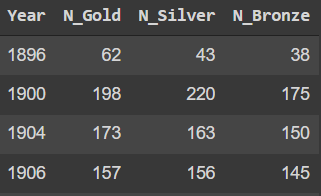

In [185]:
pd.crosstab(athlete['Year'],athlete['Medal'])

Medal,Bronze,Gold,Silver
Year,,,
1896,38,62,43
1900,175,198,220
1904,150,173,163
1906,145,157,156
1908,256,294,281
1912,300,326,315
1920,367,493,448
1924,311,332,319
1928,281,275,267


# <font color='red'>**You are Geek!**</fond>
### Provide all your answers with plots

### Find the number of winners with the gold medal in each city?

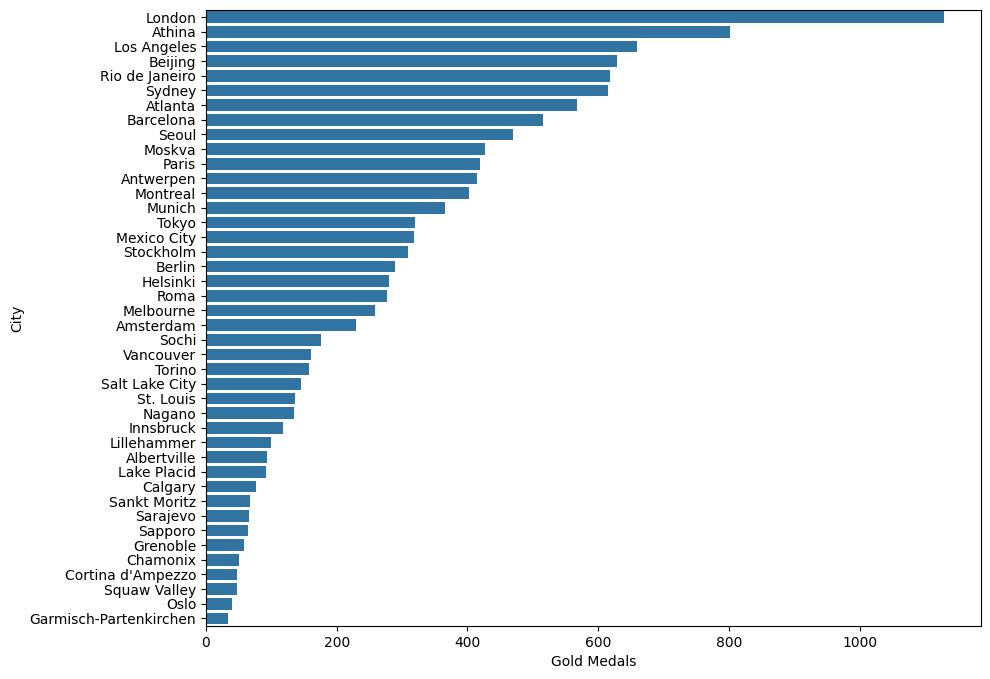

In [209]:
goldMedal = athlete[athlete['Medal'] == 'Gold']

goldCity = goldMedal.groupby('City')['ID'].nunique().sort_values(ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x=goldCity.values, y=goldCity.index)
plt.xlabel('Gold Medals')
plt.ylabel('City')
plt.show()

### Find the total missing data for each year?

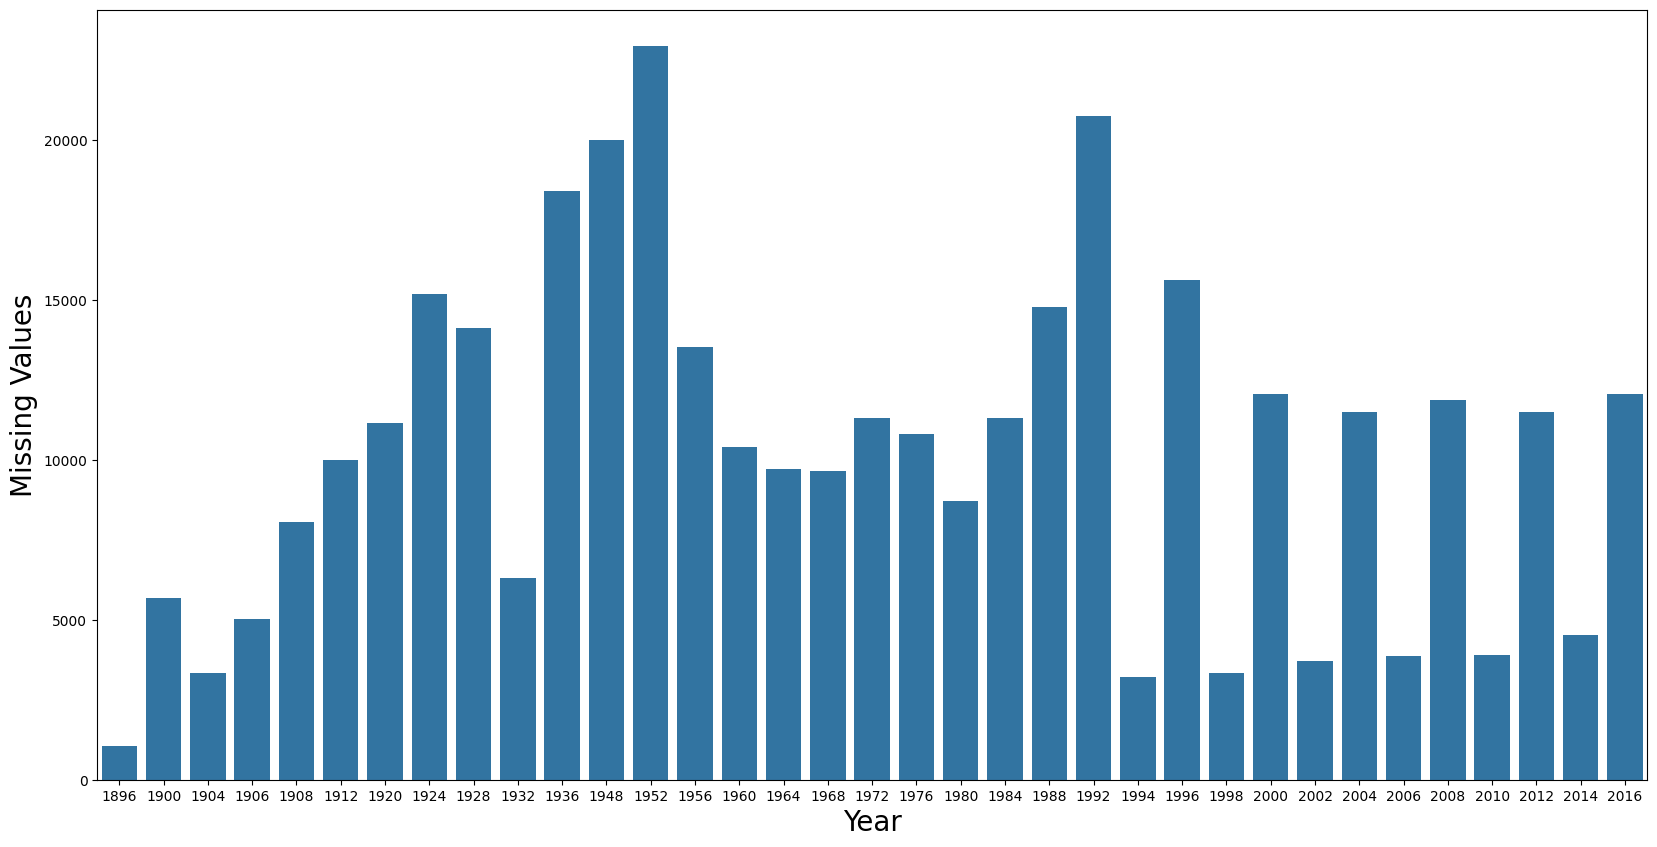

In [265]:
missing_data_per_year = athlete.isna().sum(axis=1).groupby(athlete['Year']).sum()

plt.figure(figsize=(20, 10))
sns.barplot(x=missing_data_per_year.index, y=missing_data_per_year.values,)
plt.xlabel('Year', fontsize=20)
plt.ylabel('Missing Values', fontsize=20)
plt.show()

# <font color='red'>**I dare you to solve this :)**</fond>
### Dont use for loops, and provide all your answers with plots.

### Has the number of athletes changed over time for Summer and Winter?

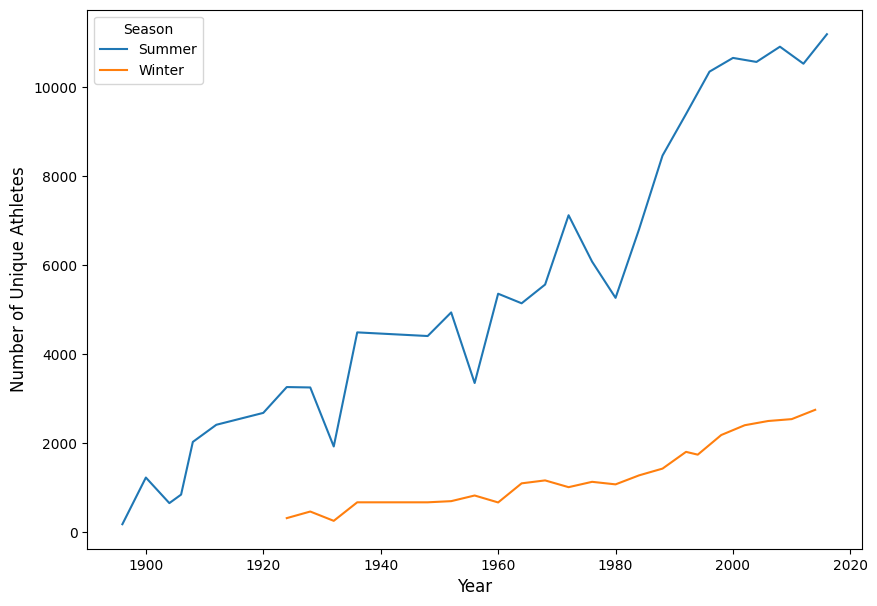

In [262]:
athletes_by_season = athlete.groupby(['Year', 'Season'])['ID'].nunique().reset_index()

plt.figure(figsize=(10, 7))
sns.lineplot(data=athletes_by_season, x='Year', y='ID', hue='Season')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Unique Athletes', fontsize=12)
plt.show()